ADVANCED VERIFICATION METRICS
Data path: /ec/vol/enscal/VERIF_PrecipType/VERIF_ptype_all/DATA_preVerif/2024_2025_49r1/
Output path: ./verification_results/

1. Loading data...
   Found 31 files
   Loaded 2,253,180 matched pairs in 0.3 seconds

2. Calculating contingency table metrics...

   Calculated contingency metrics for all thresholds

3. Creating contingency table visualizations...


/etc/ecmwf/ssd/ssd1/jupyterhub/moeg-jupyterhub/tmpdirs/moeg.22137742/ipykernel_1859410/4002462948.py:181: RuntimeWarning: Mean of empty slice
  far_vals.append(np.nanmean([m['far'] for m in day_metrics]))


   Saved: ./verification_results/contingency_metrics.png

4. Calculating sharpness...
   Saved: ./verification_results/sharpness_analysis.png

5. Calculating cost-loss analysis...
   Saved: ./verification_results/cost_loss_analysis.png

6. Calculating confusion matrices...


/etc/ecmwf/ssd/ssd1/jupyterhub/moeg-jupyterhub/tmpdirs/moeg.22137742/ipykernel_1859410/4002462948.py:368: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  df_confusion['pred_type'] = df_confusion[prob_cols].idxmax(axis=1).str.replace('prob_', '')


   Using 172,490 cases where precipitation occurred and prob > 20%

   Saved: ./verification_results/confusion_matrix.png

   Confusion matrix interpretation:
   ⚠️  When Sleet observed, predicted as Rain 55.6% of time
   ⚠️  When Sleet observed, predicted as Snow 32.1% of time
   ⚠️  When Freezing Rain observed, predicted as Rain 45.6% of time
   ⚠️  When Freezing Rain observed, predicted as Snow 42.1% of time
   ⚠️  When Freezing Drizzle observed, predicted as Rain 19.7% of time
   ⚠️  When Freezing Drizzle observed, predicted as Snow 65.9% of time
   ⚠️  When Ice Pellets observed, predicted as Rain 58.5% of time
   ⚠️  When Ice Pellets observed, predicted as Snow 18.9% of time
   ⚠️  When Ice Pellets observed, predicted as Sleet 11.3% of time
   ⚠️  When Ice Pellets observed, predicted as Freezing Rain 11.3% of time

   Overall accuracy: 92.3%

ANALYSIS COMPLETE!

Output files:
  - ./verification_results/contingency_metrics.png
  - ./verification_results/sharpness_analysis.png
  - .

/etc/ecmwf/ssd/ssd1/jupyterhub/moeg-jupyterhub/tmpdirs/moeg.22137742/ipykernel_1859410/4002462948.py:462: RuntimeWarning: Mean of empty slice
  avg_far = np.nanmean([m['far'] for m in metrics])


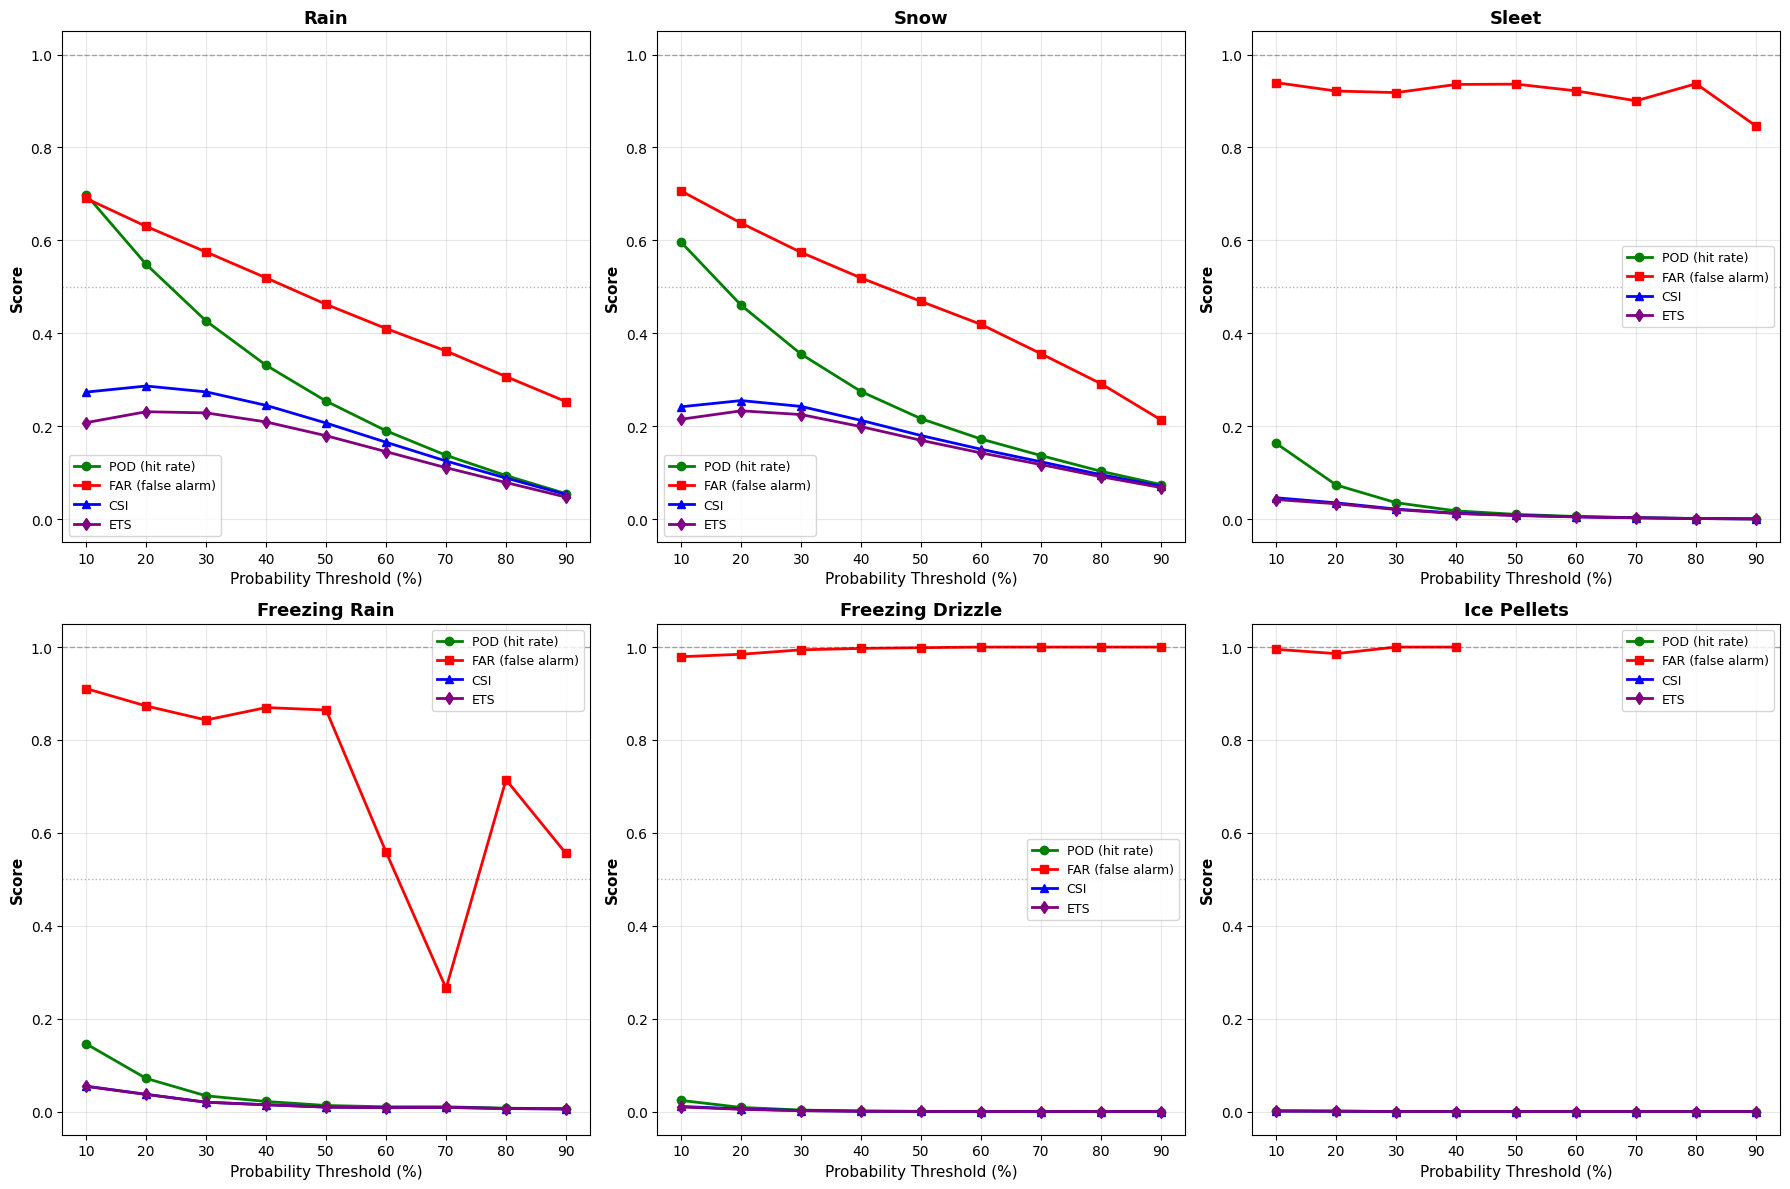

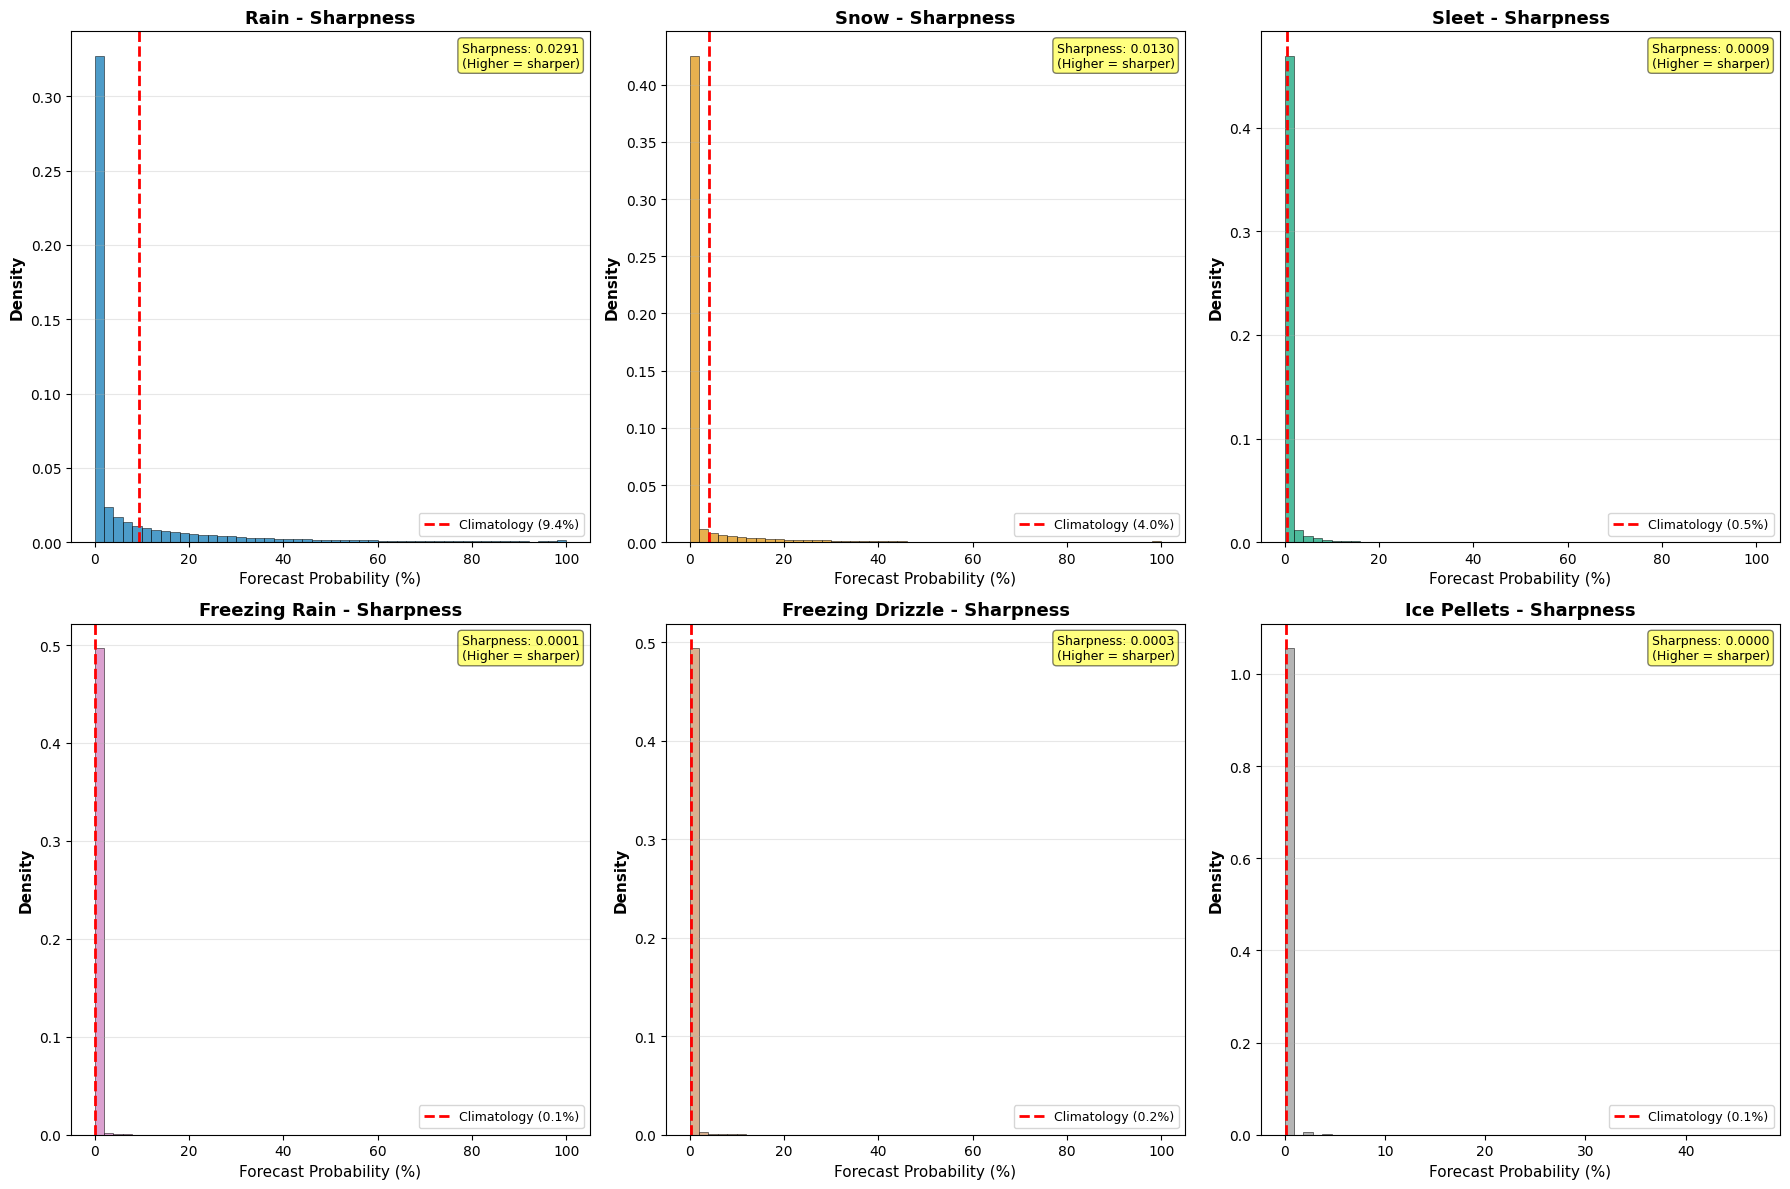

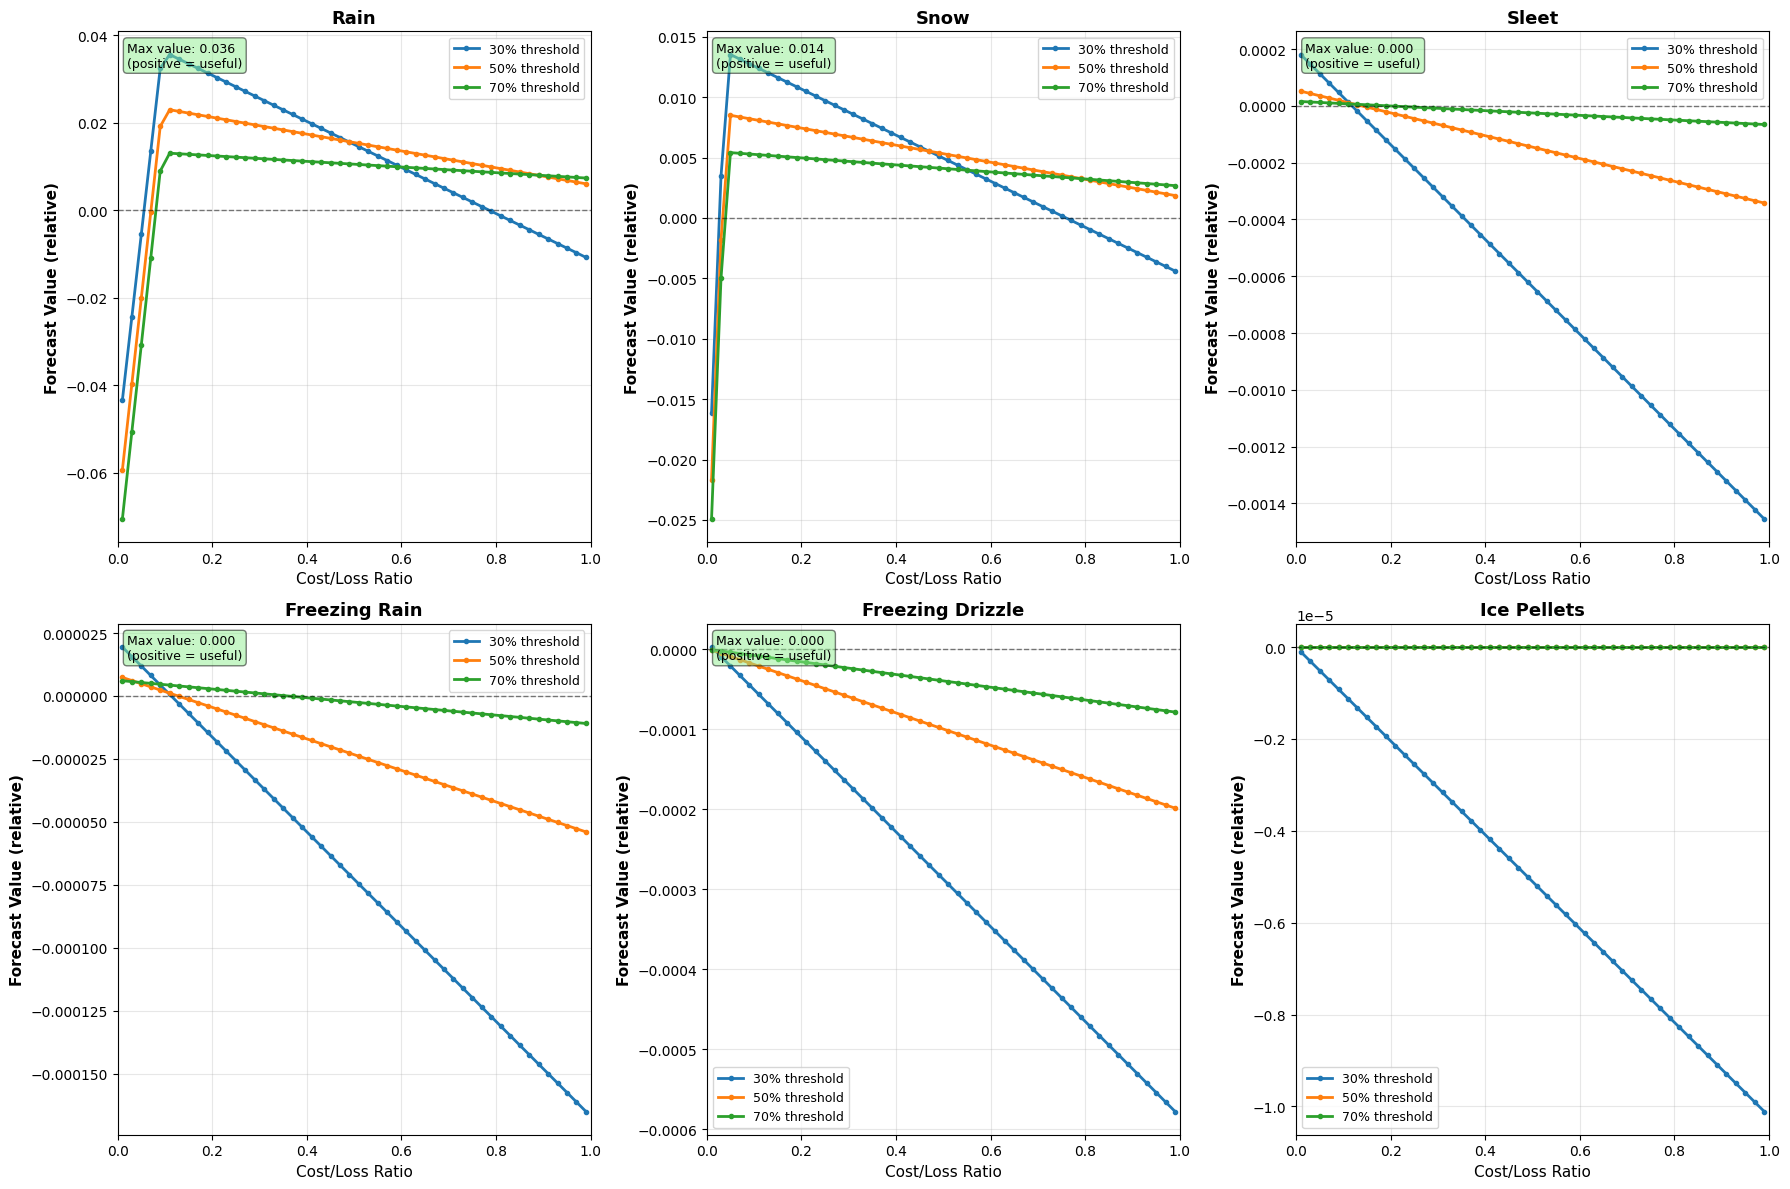

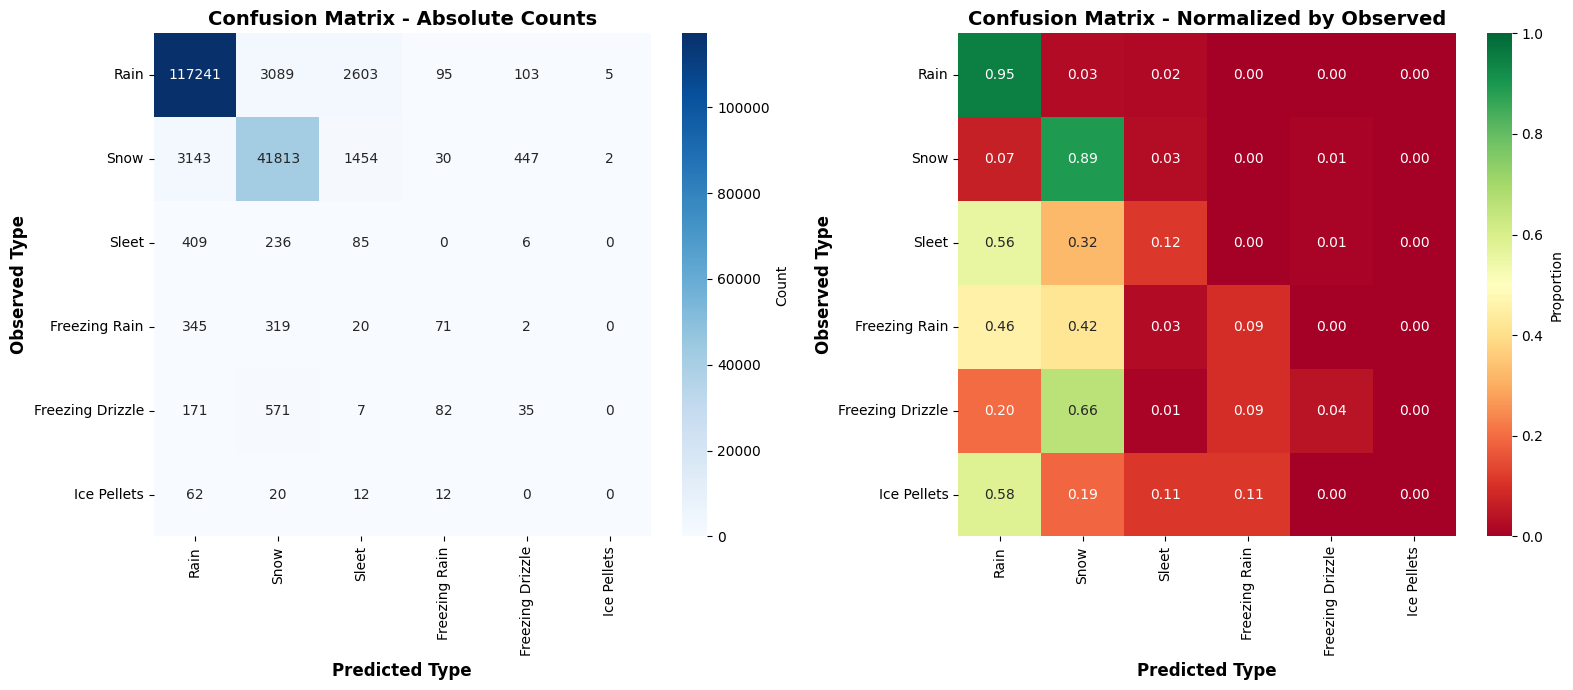

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import glob
from datetime import datetime
import os

#
# ADVANCED VERIFICATION METRICS
# ------------------------------
#
# Includes:
# 1. Contingency tables (POD, FAR, CSI/ETS at multiple thresholds)
# 2. Sharpness analysis
# 3. Cost-loss analysis
# 4. Confusion matrix (multi-category)
#
########################################

# ===== CONFIGURATION =====
DATA_PATH = "/ec/vol/enscal/VERIF_PrecipType/VERIF_ptype_all/DATA_preVerif/2024_2025_49r1/"
OUTPUT_PATH = "./verification_results/"

if not os.path.exists(OUTPUT_PATH):
    os.makedirs(OUTPUT_PATH, exist_ok=True)

PRECIP_TYPES = ['rain', 'snow', 'sleet', 'freezrain', 'freezdrizzle', 'icepellets']

COLORS = {
    'rain': '#0173B2',
    'snow': '#DE8F05',
    'sleet': '#029E73',
    'freezrain': '#CC78BC',
    'freezdrizzle': '#CA9161',
    'icepellets': '#949494'
}

NICE_NAMES = {
    'rain': 'Rain',
    'snow': 'Snow',
    'sleet': 'Sleet',
    'freezrain': 'Freezing Rain',
    'freezdrizzle': 'Freezing Drizzle',
    'icepellets': 'Ice Pellets'
}

# Thresholds for contingency tables (%)
THRESHOLDS = [10, 20, 30, 40, 50, 60, 70, 80, 90]

print("="*70)
print("ADVANCED VERIFICATION METRICS")
print("="*70)
print(f"Data path: {DATA_PATH}")
print(f"Output path: {OUTPUT_PATH}")
print()

# ===== LOAD DATA =====
print("1. Loading data...")
start_time = datetime.now()

files = sorted(glob.glob(DATA_PATH + "matched_pairs_*.parquet"))
print(f"   Found {len(files)} files")

if len(files) == 0:
    print("ERROR: No parquet files found!")
    exit(1)

df = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)

elapsed = (datetime.now() - start_time).total_seconds()
print(f"   Loaded {len(df):,} matched pairs in {elapsed:.1f} seconds")
print()

# Day groupings
day_groups = {
    1: [0, 3, 6, 9, 12, 15, 18, 21],
    2: [24, 27, 30, 33, 36, 39, 42, 45],
    3: [48, 51, 54, 57, 60, 63, 66, 69],
    4: [72, 75, 78, 81, 84, 87, 90, 93],
    5: [96, 99, 102, 105, 108, 111, 114, 117],
    6: [120, 123, 126, 129, 132, 135, 138, 141],
    7: [144, 150, 156, 162, 168]
}

days = sorted(day_groups.keys())

# ========================================================================
# 1. CONTINGENCY TABLE METRICS
# ========================================================================
print("2. Calculating contingency table metrics...")
print()

def calculate_contingency_metrics(obs, prob, threshold):
    """Calculate POD, FAR, CSI, ETS, FBI for a given threshold"""
    forecast = (prob >= threshold).astype(int)
    
    # Contingency table elements
    hits = ((forecast == 1) & (obs == 1)).sum()
    false_alarms = ((forecast == 1) & (obs == 0)).sum()
    misses = ((forecast == 0) & (obs == 1)).sum()
    correct_negatives = ((forecast == 0) & (obs == 0)).sum()
    
    # Metrics
    total_forecasts = hits + false_alarms
    total_observed = hits + misses
    
    pod = hits / total_observed if total_observed > 0 else np.nan  # Probability of Detection
    far = false_alarms / total_forecasts if total_forecasts > 0 else np.nan  # False Alarm Ratio
    csi = hits / (hits + false_alarms + misses) if (hits + false_alarms + misses) > 0 else np.nan  # Critical Success Index
    
    # Frequency Bias Index
    fbi = total_forecasts / total_observed if total_observed > 0 else np.nan
    
    # Equitable Threat Score
    n = hits + false_alarms + misses + correct_negatives
    hits_random = ((hits + false_alarms) * (hits + misses)) / n if n > 0 else 0
    ets = (hits - hits_random) / (hits + false_alarms + misses - hits_random) if (hits + false_alarms + misses - hits_random) > 0 else np.nan
    
    return {
        'hits': hits,
        'false_alarms': false_alarms,
        'misses': misses,
        'correct_negatives': correct_negatives,
        'pod': pod,
        'far': far,
        'csi': csi,
        'ets': ets,
        'fbi': fbi
    }

# Calculate for each type and threshold
contingency_results = {ptype: {thresh: [] for thresh in THRESHOLDS} for ptype in PRECIP_TYPES}

for day in days:
    steps_in_day = day_groups[day]
    df_day = df[df['forecast_step'].isin(steps_in_day)]
    
    for ptype in PRECIP_TYPES:
        obs_col = f'obs_{ptype}'
        prob_col = f'prob_{ptype}'
        
        obs = df_day[obs_col].values
        prob = df_day[prob_col].values
        
        # Remove NaN
        valid_mask = ~np.isnan(prob)
        obs_valid = obs[valid_mask]
        prob_valid = prob[valid_mask]
        
        if len(obs_valid) > 0:
            for thresh in THRESHOLDS:
                metrics = calculate_contingency_metrics(obs_valid, prob_valid, thresh)
                contingency_results[ptype][thresh].append(metrics)

print("   Calculated contingency metrics for all thresholds")
print()

# ===== PLOT CONTINGENCY METRICS =====
print("3. Creating contingency table visualizations...")

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, ptype in enumerate(PRECIP_TYPES):
    ax = axes[idx]
    
    # Aggregate across days for each threshold
    pod_vals = []
    far_vals = []
    csi_vals = []
    ets_vals = []
    fbi_vals = []
    
    for thresh in THRESHOLDS:
        day_metrics = contingency_results[ptype][thresh]
        if len(day_metrics) > 0:
            # Average across days
            pod_vals.append(np.nanmean([m['pod'] for m in day_metrics]))
            far_vals.append(np.nanmean([m['far'] for m in day_metrics]))
            csi_vals.append(np.nanmean([m['csi'] for m in day_metrics]))
            ets_vals.append(np.nanmean([m['ets'] for m in day_metrics]))
            fbi_vals.append(np.nanmean([m['fbi'] for m in day_metrics]))
        else:
            pod_vals.append(np.nan)
            far_vals.append(np.nan)
            csi_vals.append(np.nan)
            ets_vals.append(np.nan)
            fbi_vals.append(np.nan)
    
    # Plot
    ax.plot(THRESHOLDS, pod_vals, marker='o', linewidth=2, label='POD (hit rate)', color='green')
    ax.plot(THRESHOLDS, far_vals, marker='s', linewidth=2, label='FAR (false alarm)', color='red')
    ax.plot(THRESHOLDS, csi_vals, marker='^', linewidth=2, label='CSI', color='blue')
    ax.plot(THRESHOLDS, ets_vals, marker='d', linewidth=2, label='ETS', color='purple')
    
    ax.axhline(y=1.0, color='black', linestyle='--', linewidth=1, alpha=0.3)
    ax.axhline(y=0.5, color='black', linestyle=':', linewidth=1, alpha=0.3)
    
    ax.set_xlabel('Probability Threshold (%)', fontsize=11)
    ax.set_ylabel('Score', fontsize=11, fontweight='bold')
    ax.set_title(NICE_NAMES[ptype], fontsize=13, fontweight='bold')
    ax.set_ylim([-0.05, 1.05])
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best', fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_PATH + 'contingency_metrics.png', dpi=300, bbox_inches='tight')
print(f"   Saved: {OUTPUT_PATH}contingency_metrics.png")
print()

# ========================================================================
# 2. SHARPNESS ANALYSIS
# ========================================================================
print("4. Calculating sharpness...")

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

sharpness_results = {}

for idx, ptype in enumerate(PRECIP_TYPES):
    ax = axes[idx]
    
    prob_col = f'prob_{ptype}'
    obs_col = f'obs_{ptype}'
    
    # Get all probabilities
    probs = df[prob_col].values
    probs_clean = probs[~np.isnan(probs)]
    
    obs = df[obs_col].values
    climatology = obs.mean()
    
    # Sharpness = variance of forecast probabilities
    sharpness = np.var(probs_clean / 100.0)
    sharpness_results[ptype] = sharpness
    
    # Plot histogram
    ax.hist(probs_clean, bins=50, color=COLORS[ptype], alpha=0.7, 
            edgecolor='black', linewidth=0.5, density=True)
    
    # Add climatology line
    ax.axvline(x=climatology*100, color='red', linestyle='--', linewidth=2, 
               label=f'Climatology ({climatology*100:.1f}%)')
    
    ax.set_xlabel('Forecast Probability (%)', fontsize=11)
    ax.set_ylabel('Density', fontsize=11, fontweight='bold')
    ax.set_title(f'{NICE_NAMES[ptype]} - Sharpness', fontsize=13, fontweight='bold')
    ax.grid(True, alpha=0.3, axis='y')
    ax.legend(loc='best', fontsize=9)
    
    # Add sharpness value
    ax.text(0.98, 0.98, f'Sharpness: {sharpness:.4f}\n(Higher = sharper)', 
            transform=ax.transAxes, fontsize=9,
            verticalalignment='top', horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.5))

plt.tight_layout()
plt.savefig(OUTPUT_PATH + 'sharpness_analysis.png', dpi=300, bbox_inches='tight')
print(f"   Saved: {OUTPUT_PATH}sharpness_analysis.png")
print()

# ========================================================================
# 3. COST-LOSS ANALYSIS
# ========================================================================
print("5. Calculating cost-loss analysis...")

def calculate_forecast_value(obs, prob, threshold, cost_loss_ratio):
    """Calculate economic value for given threshold and C/L ratio"""
    forecast = (prob >= threshold).astype(int)
    
    hits = ((forecast == 1) & (obs == 1)).sum()
    false_alarms = ((forecast == 1) & (obs == 0)).sum()
    misses = ((forecast == 0) & (obs == 1)).sum()
    
    # Expense using forecast
    expense_forecast = false_alarms * cost_loss_ratio + misses
    
    # Expense using climatology (always or never protect)
    n_events = obs.sum()
    n_total = len(obs)
    
    # Strategy 1: Never protect
    expense_never = n_events  # Miss all events
    
    # Strategy 2: Always protect
    expense_always = n_total * cost_loss_ratio
    
    # Use better climatology strategy
    expense_climatology = min(expense_never, expense_always)
    
    # Value = savings compared to climatology
    value = (expense_climatology - expense_forecast) / n_total
    
    return value

# Cost-loss ratios to test
cl_ratios = np.linspace(0.01, 0.99, 50)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, ptype in enumerate(PRECIP_TYPES):
    ax = axes[idx]
    
    prob_col = f'prob_{ptype}'
    obs_col = f'obs_{ptype}'
    
    obs = df[obs_col].values
    prob = df[prob_col].values
    
    # Remove NaN
    valid_mask = ~np.isnan(prob)
    obs_valid = obs[valid_mask]
    prob_valid = prob[valid_mask]
    
    if len(obs_valid) > 0:
        # Calculate value for different thresholds
        for thresh in [30, 50, 70]:
            values = []
            for cl in cl_ratios:
                val = calculate_forecast_value(obs_valid, prob_valid, thresh, cl)
                values.append(val)
            
            ax.plot(cl_ratios, values, linewidth=2, label=f'{thresh}% threshold', marker='o', markersize=3)
        
        # Zero line
        ax.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5)
        
        ax.set_xlabel('Cost/Loss Ratio', fontsize=11)
        ax.set_ylabel('Forecast Value (relative)', fontsize=11, fontweight='bold')
        ax.set_title(NICE_NAMES[ptype], fontsize=13, fontweight='bold')
        ax.grid(True, alpha=0.3)
        ax.legend(loc='best', fontsize=9)
        ax.set_xlim([0, 1])
        
        # Add interpretation text
        max_value = max([max(ax.lines[i].get_ydata()) for i in range(len(ax.lines)-1)])
        if max_value > 0:
            ax.text(0.02, 0.98, f'Max value: {max_value:.3f}\n(positive = useful)', 
                    transform=ax.transAxes, fontsize=9,
                    verticalalignment='top',
                    bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))

plt.tight_layout()
plt.savefig(OUTPUT_PATH + 'cost_loss_analysis.png', dpi=300, bbox_inches='tight')
print(f"   Saved: {OUTPUT_PATH}cost_loss_analysis.png")
print()

# ========================================================================
# 4. CONFUSION MATRIX
# ========================================================================
print("6. Calculating confusion matrices...")

# For confusion matrix, we need to determine the "most likely" type for each observation
# Use highest probability as predicted type

# Map to simple categories for cleaner visualization
df_confusion = df.copy()

# Get the precipitation type with highest probability
prob_cols = [f'prob_{ptype}' for ptype in PRECIP_TYPES]
obs_cols = [f'obs_{ptype}' for ptype in PRECIP_TYPES]

# Find predicted type (highest probability)
df_confusion['pred_type'] = df_confusion[prob_cols].idxmax(axis=1).str.replace('prob_', '')

# Find observed type (1 if any, 0 if none, or the first one if multiple)
def get_observed_type(row):
    for ptype in PRECIP_TYPES:
        if row[f'obs_{ptype}'] == 1:
            return ptype
    return 'none'

df_confusion['obs_type'] = df_confusion.apply(get_observed_type, axis=1)

# Filter to cases where something was observed (remove 'none')
df_confusion_events = df_confusion[df_confusion['obs_type'] != 'none']

# Also filter to cases where probability > 20% for any type (actual forecasts)
max_prob = df_confusion_events[prob_cols].max(axis=1)
df_confusion_events = df_confusion_events[max_prob > 20]

print(f"   Using {len(df_confusion_events):,} cases where precipitation occurred and prob > 20%")
print()

# Create confusion matrix
if len(df_confusion_events) > 0:
    labels = PRECIP_TYPES
    cm = confusion_matrix(df_confusion_events['obs_type'], 
                          df_confusion_events['pred_type'],
                          labels=labels)
    
    # Normalize by row (observed type)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    
    # Plot both absolute and normalized
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
    
    # Absolute counts
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=[NICE_NAMES[p] for p in labels],
                yticklabels=[NICE_NAMES[p] for p in labels],
                ax=ax1, cbar_kws={'label': 'Count'})
    ax1.set_xlabel('Predicted Type', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Observed Type', fontsize=12, fontweight='bold')
    ax1.set_title('Confusion Matrix - Absolute Counts', fontsize=14, fontweight='bold')
    
    # Normalized (percentages)
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='RdYlGn', 
                xticklabels=[NICE_NAMES[p] for p in labels],
                yticklabels=[NICE_NAMES[p] for p in labels],
                ax=ax2, cbar_kws={'label': 'Proportion'}, vmin=0, vmax=1)
    ax2.set_xlabel('Predicted Type', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Observed Type', fontsize=12, fontweight='bold')
    ax2.set_title('Confusion Matrix - Normalized by Observed', fontsize=14, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(OUTPUT_PATH + 'confusion_matrix.png', dpi=300, bbox_inches='tight')
    print(f"   Saved: {OUTPUT_PATH}confusion_matrix.png")
    
    # Print interpretation
    print()
    print("   Confusion matrix interpretation:")
    for i, obs_type in enumerate(labels):
        for j, pred_type in enumerate(labels):
            if i != j and cm_normalized[i, j] > 0.1:  # More than 10% confusion
                print(f"   ⚠️  When {NICE_NAMES[obs_type]} observed, predicted as {NICE_NAMES[pred_type]} {cm_normalized[i,j]*100:.1f}% of time")
    
    # Calculate accuracy
    accuracy = np.trace(cm) / np.sum(cm)
    print()
    print(f"   Overall accuracy: {accuracy*100:.1f}%")
else:
    print("   Not enough data for confusion matrix")

print()

# ========================================================================
# SUMMARY REPORT
# ========================================================================
print("="*70)
print("ANALYSIS COMPLETE!")
print("="*70)
print()
print("Output files:")
print(f"  - {OUTPUT_PATH}contingency_metrics.png")
print(f"  - {OUTPUT_PATH}sharpness_analysis.png")
print(f"  - {OUTPUT_PATH}cost_loss_analysis.png")
print(f"  - {OUTPUT_PATH}confusion_matrix.png")
print()

print("Summary:")
print()
print("1. CONTINGENCY METRICS (at 50% threshold):")
for ptype in PRECIP_TYPES:
    if 50 in contingency_results[ptype] and len(contingency_results[ptype][50]) > 0:
        metrics = contingency_results[ptype][50]
        avg_pod = np.nanmean([m['pod'] for m in metrics])
        avg_far = np.nanmean([m['far'] for m in metrics])
        avg_csi = np.nanmean([m['csi'] for m in metrics])
        print(f"   {NICE_NAMES[ptype]:20s}: POD={avg_pod:.3f}, FAR={avg_far:.3f}, CSI={avg_csi:.3f}")

print()
print("2. SHARPNESS:")
for ptype in PRECIP_TYPES:
    if ptype in sharpness_results:
        sharp = sharpness_results[ptype]
        interpretation = "Sharp (good)" if sharp > 0.01 else "Hedged (poor)"
        print(f"   {NICE_NAMES[ptype]:20s}: {sharp:.4f} ({interpretation})")

print()
print("Interpretation Guide:")
print("  POD (Probability of Detection): Higher is better (1.0 = perfect)")
print("  FAR (False Alarm Ratio): Lower is better (0.0 = perfect)")
print("  CSI (Critical Success Index): Higher is better (1.0 = perfect)")
print("  ETS (Equitable Threat Score): Higher is better, removes random hits")
print("  Sharpness: Higher = more confident/sharp forecasts")
print("  Cost-Loss Value: Positive = forecast adds value over climatology")
print("  Confusion Matrix: Diagonal = correct predictions")
